# SSQM v2.0
## Using NBA Shooting Data: Considers shot type, closest defender distance and touch time
## Bin shots by filtering each condition combination and then use that for SSQM

In [1]:
import os, sys

sys.path.append(os.path.dirname(os.path.dirname(os.path.abspath("__file__"))))
from nbafuns import *
from nba_api.stats.endpoints import playerdashptshots, leaguedashplayerbiostats

pd.options.mode.chained_assignment = None

data_DIR1 = "../data/box/"
data_DIR2 = "../data/shots/"
csv_export_DIR = "C:/Users/pansr/Documents/repos/csv/"
img_DIR_P = "../data/images/players/"
fig_DIR = "../figs/playoffs/"

In [2]:
league = "NBA"
player_dict = get_players_pbp(league=league)
teams_dict, teams_list = get_teams(league="NBA")

In [3]:
season = 2024
season_str = get_ss(season)

In [4]:
dft = pd.read_parquet(data_DIR1 + f"NBA_Box_P_Cum_Base_{season}_PS.parquet", columns = ["PLAYER_ID","TEAM_ID"])
df = pd.read_parquet(data_DIR2 + f"{league}_Shots_{season}_All_PS.parquet")
dfd = pd.read_parquet(data_DIR2 + f"{league}_Shots_{season}_overall_PS.parquet", columns = ["PLAYER_ID","FGM","FGA"])
dfd = dfd.sort_values(by = "PLAYER_ID").reset_index(drop=True)

In [5]:
df = df[["PLAYER_ID","PLAYER_NAME","PLAYER_LAST_TEAM_ID","FGM","FGA","FG2M","FG2A","FG3M","FG3A", 'general_range', 'closest_def', 'touch_time']]
df = df.query("general_range != 'Other'")
df_avg = df.groupby(['general_range', 'closest_def', 'touch_time']).sum()
df_avg = df_avg.drop(columns= ["PLAYER_ID","PLAYER_NAME","PLAYER_LAST_TEAM_ID"])
df_avg["xFG2"] = df_avg["FG2M"]/df_avg["FG2A"]
df_avg["xFG3"] = df_avg["FG3M"]/df_avg["FG3A"]
df_avg = df_avg.drop(columns =["FGM","FGA","FG2M","FG2A","FG3M","FG3A"])
df_avg = df_avg.reset_index()

In [6]:
# df_avg

In [7]:
shots = pd.merge(df,df_avg,on=['general_range', 'closest_def', 'touch_time'])
shots["FG2_PCT"] = shots["FG2M"]/shots["FG2A"]
shots["FG3_PCT"] = shots["FG3M"]/shots["FG3A"]
shots = shots.replace([np.inf, -np.inf], np.nan)
shots = shots.fillna(0)
shots["PTS2"] =  (2*shots["FG2A"]*shots["FG2_PCT"]).round(2)
shots["PTS3"] =  (3*shots["FG3A"]*shots["FG3_PCT"]).round(2)
shots["PTS"] =  (2*shots["FG2A"]*shots["FG2_PCT"] + 3*shots["FG3A"]*shots["FG3_PCT"]).round(2)
shots["xPTS2"] = (2*shots["FG2A"]*shots["xFG2"]).round(2)
shots["xPTS3"] = (3*shots["FG3A"]*shots["xFG3"]).round(2)
shots["xPTS"] = (2*shots["FG2A"]*shots["xFG2"] + 3*shots["FG3A"]*shots["xFG3"]).round(2)

In [8]:
# shots.query("PLAYER_NAME == 'LeBron James'")

In [9]:
fg = (shots
    .groupby(['PLAYER_ID'])[['FGM', 'FGA', 'PTS', 'xPTS']]
    .agg({'FGM': ["sum"], 'FGA': ["sum"], 'PTS': ["sum"], 'xPTS': ["sum"]}))
fg.columns = ['FGM', 'FGA', 'PTS', 'xPTS']
fg['eFG'] = np.round(fg['PTS']/fg['FGA']/2, 3)
fg['xeFG'] = np.round(fg['xPTS']/fg['FGA']/2, 3)
fg['Shot_Making'] = np.round((fg['PTS'] - fg['xPTS'])/fg['FGA'], 3)

In [10]:

fg = fg.drop(columns=['FGM', 'FGA'])
fg = fg.fillna(0)
fg = pd.merge(dfd,fg,on=["PLAYER_ID"])
fg["Points_Added"] = fg["Shot_Making"]* fg["FGA"]
fg["PTS"] = fg["PTS"].astype(int)
fg = fg.reset_index()
fg["Player"] = fg["PLAYER_ID"].map(player_dict)
fg.insert(1,"Player",fg.pop("Player"))
fg = pd.merge(fg,dft,on="PLAYER_ID")
fg["Team"] = fg["TEAM_ID"].map(teams_dict)
fg.insert(2,"Team",fg.pop("Team"))
fg[['Points_Added']] = fg[['Points_Added']].round(1)
fg[['Shot_Making']] = fg[['Shot_Making']].round(3)
fg = fg.drop(columns=["TEAM_ID"])

In [11]:
# sdfdsfsdf

In [12]:
df = fg.iloc[:,1:].query("PTS > 200").nlargest(10,columns="Shot_Making").reset_index(drop=True).drop(columns="PLAYER_ID")
df.index += 1
# print(df.to_markdown())

## Points Added

In [13]:
df_e = fg.iloc[:,1:].nlargest(15,columns="Points_Added").reset_index(drop=True).reset_index()
df_e = df_e.drop(columns=["FGM","FGA","PTS","xPTS"])
df_e["index"] += 1
df_e["PLAYER_ID"] = df_e["PLAYER_ID"].astype(str)
# df_e["xPTS"] = df_e["xPTS"].round(1)

GT(_tbl_data=    index                 Player                    Team PLAYER_ID    eFG  \
0       1          Stephen Curry   Golden State Warriors    201939  0.600   
1       2          Kawhi Leonard             LA Clippers    202695  0.605   
2       3          Aaron Nesmith          Indiana Pacers   1630174  0.700   
3       4         Gary Trent Jr.         Milwaukee Bucks   1629018  0.694   
4       5  Giannis Antetokounmpo         Milwaukee Bucks    203507  0.617   
5       6           Jamal Murray          Denver Nuggets   1627750  0.543   
6       7            Evan Mobley     Cleveland Cavaliers   1630596  0.679   
7       8          Fred VanVleet         Houston Rockets   1627832  0.575   
8       9        Davion Mitchell              Miami Heat   1630558  0.695   
9      10               AJ Green         Milwaukee Bucks   1631260  0.692   
10     11        Jaden McDaniels  Minnesota Timberwolves   1630183  0.620   
11     12              Max Strus     Cleveland Cavaliers   1629622  0.614   
12     13               Naz Reid  Minnesota Timberwolves   1629675  0.653   
13     14             Isaiah Joe   Oklahoma City Thunder   1630198  0.706   
14     15       Donovan Mitchell     Cleveland Cavaliers   1628378  0.547   

     xeFG  Shot_Making  Points_Added  
0   0.476        0.247          32.1  
1   0.483        0.245          30.1  
2   0.544        0.312          25.0  
3   0.511        0.364          22.6  
4   0.513        0.208          20.6  
5   0.488        0.110          19.0  
6   0.562        0.235          16.0  
7   0.493        0.164          15.3  
8   0.511        0.369          15.1  
9   0.498        0.388          15.1  
10  0.530        0.180          14.9  
11  0.517        0.196          13.9  
12  0.545        0.217          13.5  
13  0.510        0.391          13.3  
14  0.506        0.083          13.1  , _body=<great_tables._gt_data.Body object at 0x000001CBBDFF0220>, _boxhead=Boxhead([ColInfo(var='index', type=<ColInfoTypeEnum.default: 1>, column_label='#', column_align='center', column_width=None), ColInfo(var='Player', type=<ColInfoTypeEnum.default: 1>, column_label='Player', column_align='left', column_width=None), ColInfo(var='Team', type=<ColInfoTypeEnum.default: 1>, column_label='Team', column_align='center', column_width=None), ColInfo(var='PLAYER_ID', type=<ColInfoTypeEnum.default: 1>, column_label='', column_align='center', column_width=None), ColInfo(var='eFG', type=<ColInfoTypeEnum.default: 1>, column_label='eFG%', column_align='center', column_width=None), ColInfo(var='xeFG', type=<ColInfoTypeEnum.default: 1>, column_label='xeFG%', column_align='center', column_width=None), ColInfo(var='Shot_Making', type=<ColInfoTypeEnum.default: 1>, column_label='Shot Making', column_align='center', column_width=None), ColInfo(var='Points_Added', type=<ColInfoTypeEnum.default: 1>, column_label='Points Added', column_align='center', column_width=None)]), _stub=<great_tables._gt_data.Stub object at 0x000001CBBD3DBEB0>, _spanners=Spanners([]), _heading=Heading(title=Md(text='**Best Volume Shot Makers Playoffs 2024-25**'), subtitle='Based on SSQM v2.0 | Shot Making: Points per shot (PPS) above league average', preheader=None), _stubhead=None, _source_notes=['eFG%: Effective Field Goal % | xeFG%: Expected eFG% | xPTS: Expected Points', 'Simple Shot Quality Model: SSQM v2.0 is based on shot type, defender distance & touch time', 'socials:sradjoker | source: nba.com/stats'], _footnotes=[], _styles=[StyleInfo(locname=LocBody(columns='Shot_Making', rows=[0], mask=None), grpname=None, colname='Shot_Making', rownum=0, colnum=None, styles=[CellStyleText(color='#000000', font=None, size=None, align=None, v_align=None, style=None, weight=None, stretch=None, decorate=None, transform=None, whitespace=None), CellStyleFill(color='#f9eee7')]), StyleInfo(locname=LocBody(columns='Shot_Making', rows=[1], mask=None), grpname=None, colname='Shot_Making', rownum=1, colnum=None, styles=[CellStyleText(color='#000000', fo
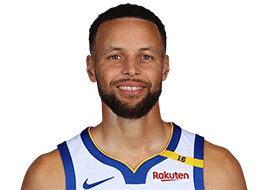
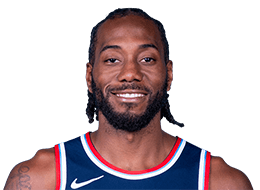
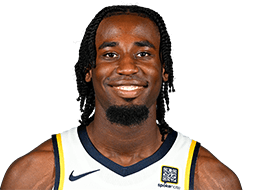
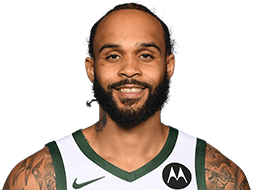
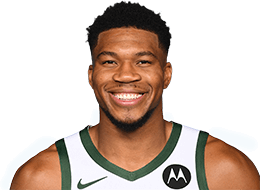
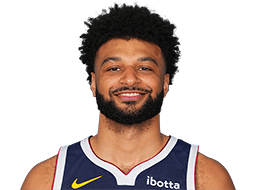
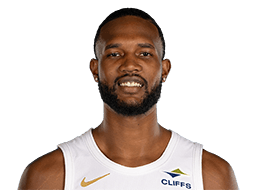
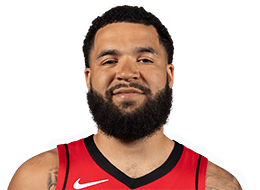
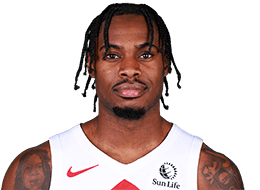
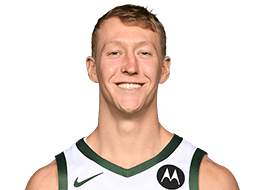
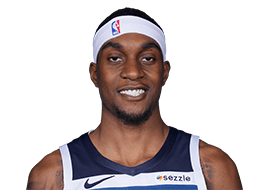
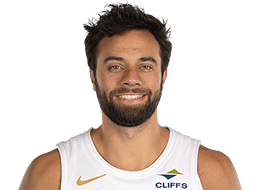
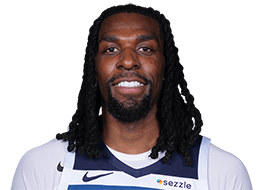
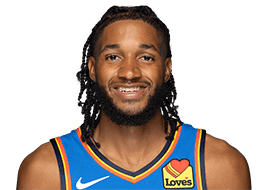
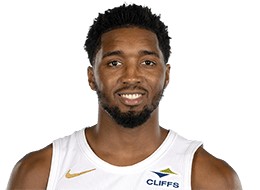

In [14]:
t = (
    GT(df_e)
    .tab_header(
        title = md(f"**Best Volume Shot Makers Playoffs {season_str}**"),
        subtitle = "Based on SSQM v2.0 | Shot Making: Points per shot (PPS) above league average"
    )
    .tab_source_note(source_note = "eFG%: Effective Field Goal % | xeFG%: Expected eFG% | xPTS: Expected Points")
    .tab_source_note(source_note = "Simple Shot Quality Model: SSQM v2.0 is based on shot type, defender distance & touch time" )
    .tab_source_note(source_note="socials:sradjoker | source: nba.com/stats")
    .cols_label(
        index = "#",
        PLAYER_ID = "",
        eFG="eFG%",
        xeFG="xeFG%",
        Shot_Making = "Shot Making",
        Points_Added = "Points Added",
    )
    .fmt_percent(
      columns=["eFG","xeFG"],
      decimals=1
    )
    .data_color(
        columns=['Shot_Making'],
        palette="RdBu",
        reverse="False"
    )
    .fmt_image(
        columns="PLAYER_ID",
        path = img_DIR_P,
        file_pattern="{}.png"
    )
    .cols_align(align="center")
    .cols_align(align="left", columns="Player")
    .tab_options(
        heading_title_font_size="150%",
        heading_subtitle_font_size="110%",
        # heading_title_font_weight='bold',
        table_background_color="floralwhite",
        column_labels_font_size="105%",
        column_labels_font_weight='bold',
        row_group_font_weight='bold',
        row_group_background_color="#E5E1D8",
        table_font_size=10,
        table_font_names="Consolas", 
        data_row_padding = "2px",
        # table_margin_left = 7,
        # table_margin_right = 0,
    )
)
t.save(fig_DIR + f"ssqm2_points_added_{season}_PS.png",scale=3,web_driver="firefox")
t

In [18]:
df_e = fg.iloc[:,1:].nsmallest(15,columns="Points_Added").reset_index(drop=True).reset_index()
df_e["index"] += 1
df_e["PLAYER_ID"] = df_e["PLAYER_ID"].astype(str)
df_e["xPTS"] = df_e["xPTS"].round(1)

GT(_tbl_data=    index                    Player                    Team PLAYER_ID  FGM  \
0       1          Donte DiVincenzo  Minnesota Timberwolves   1628978   21   
1       2        Kristaps Porzingis          Boston Celtics    204001   22   
2       3              Desmond Bane       Memphis Grizzlies   1630217   20   
3       4            Draymond Green   Golden State Warriors    203110   31   
4       5            Alperen Sengun         Houston Rockets   1630578   59   
5       6              Jimmy Butler   Golden State Warriors    202710   47   
6       7             Luguentz Dort   Oklahoma City Thunder   1629652   17   
7       8                Al Horford          Boston Celtics    201143   18   
8       9        Brandin Podziemski   Golden State Warriors   1641764   33   
9      10           Christian Braun          Denver Nuggets   1631128   45   
10     11                Kyle Kuzma         Milwaukee Bucks   1628398   12   
11     12  Nickeil Alexander-Walker  Minnesota Timberwolves   1629638   16   
12     13            Damian Lillard         Milwaukee Bucks    203081    6   
13     14              Quinten Post   Golden State Warriors   1642366   13   
14     15               Moses Moody   Golden State Warriors   1630541   24   

    FGA  PTS   xPTS    eFG   xeFG  Shot_Making  Points_Added  
0    70   52   75.2  0.371  0.537       -0.331         -23.2  
1    63   47   65.7  0.385  0.538       -0.306         -19.3  
2    63   44   61.1  0.367  0.509       -0.286         -18.0  
3    79   72   88.2  0.468  0.573       -0.211         -16.7  
4   131  116  131.9  0.457  0.519       -0.125         -16.4  
5   106   98  112.9  0.471  0.543       -0.144         -15.3  
6    54   46   59.3  0.434  0.560       -0.252         -13.6  
7    47   42   55.1  0.447  0.586       -0.279         -13.1  
8    89   80   92.5  0.471  0.544       -0.147         -13.1  
9    97  100  112.2  0.521  0.584       -0.127         -12.3  
10   35   26   37.2  0.371  0.532       -0.320         -11.2  
11   50   41   52.2  0.410  0.522       -0.224         -11.2  
12   27   15   25.9  0.278  0.479       -0.402         -10.9  
13   40   34   44.8  0.425  0.560       -0.270         -10.8  
14   71   60   70.3  0.423  0.495       -0.145         -10.3  , _body=<great_tables._gt_data.Body object at 0x000001CBBF6F6890>, _boxhead=Boxhead([ColInfo(var='index', type=<ColInfoTypeEnum.default: 1>, column_label='#', column_align='center', column_width=None), ColInfo(var='Player', type=<ColInfoTypeEnum.default: 1>, column_label='Player', column_align='left', column_width=None), ColInfo(var='Team', type=<ColInfoTypeEnum.default: 1>, column_label='Team', column_align='center', column_width=None), ColInfo(var='PLAYER_ID', type=<ColInfoTypeEnum.default: 1>, column_label='', column_align='center', column_width=None), ColInfo(var='FGM', type=<ColInfoTypeEnum.default: 1>, column_label='FGM', column_align='center', column_width=None), ColInfo(var='FGA', type=<ColInfoTypeEnum.default: 1>, column_label='FGA', column_align='center', column_width=None), ColInfo(var='PTS', type=<ColInfoTypeEnum.default: 1>, column_label='PTS', column_align='center', column_width=None), ColInfo(var='xPTS', type=<ColInfoTypeEnum.default: 1>, column_label='xPTS', column_align='center', column_width=None), ColInfo(var='eFG', type=<ColInfoTypeEnum.default: 1>, column_label='eFG%', column_align='center', column_width=None), ColInfo(var='xeFG', type=<ColInfoTypeEnum.default: 1>, column_label='xeFG%', column_align='center', column_width=None), ColInfo(var='Shot_Making', type=<ColInfoTypeEnum.default: 1>, column_label='Shot Making', column_align='center', column_width=None), ColInfo(var='Points_Added', type=<ColInfoTypeEnum.default: 1>, column_label='Points Added', column_align='center', column_width=None)]), _stub=<great_tables._gt_data.Stub object at 0x000001CBBF8876D0>, _spanners=Spanners([]), _heading=Heading(title=Md(text='**Worst Volume Shot Makers Playoffs 2024-25**'), subtitle='Based on SS
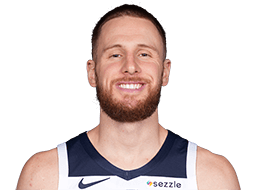
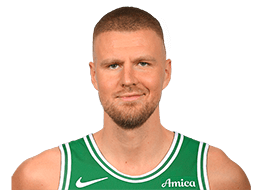
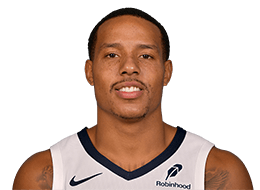
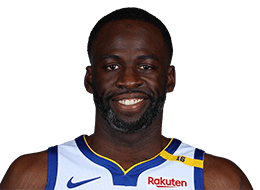
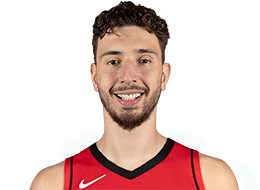
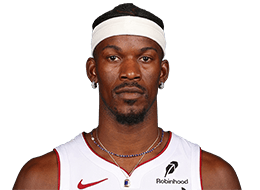
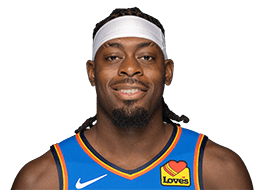
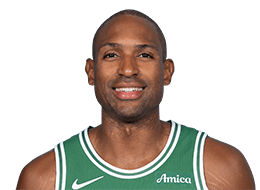
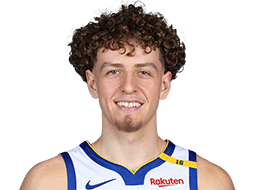
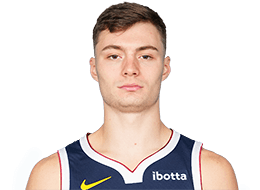
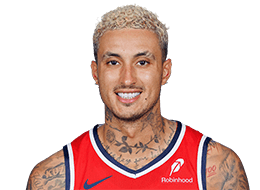
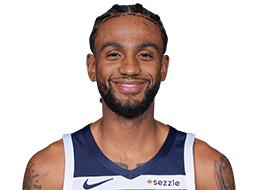
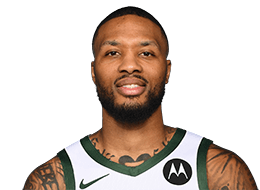
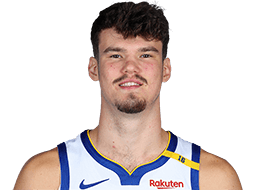
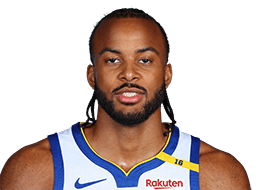

In [19]:
t = (
    GT(df_e)
    .tab_header(
        title = md(f"**Worst Volume Shot Makers Playoffs {season_str}**"),
        subtitle = "Based on SSQM v2.0 | Shot Making: Points per shot (PPS) above league average"
    )
    .tab_source_note(source_note = "eFG%: Effective Field Goal % | xeFG%: Expected eFG% | xPTS: Expected Points")
    .tab_source_note(source_note = "Simple Shot Quality Model: SSQM v2.0 is based on shot type, defender distance & touch time" )
    .tab_source_note(source_note="bsky:@sradjoker.cc | X:@sradjoker | source: nba.com/stats")
    .cols_label(
        index = "#",
        PLAYER_ID = "",
        eFG="eFG%",
        xeFG="xeFG%",
        Shot_Making = "Shot Making",
        Points_Added = "Points Added",
    )
    .fmt_percent(
      columns=["eFG","xeFG"],
      decimals=1
    )
    .data_color(
        columns=['Shot_Making'],
        palette="RdBu",
        reverse="False"
    )
    .fmt_image(
        columns="PLAYER_ID",
        path = img_DIR_P,
        file_pattern="{}.png"
    )
    .cols_align(align="center")
    .cols_align(align="left", columns="Player")
    .tab_options(
        heading_title_font_size="150%",
        heading_subtitle_font_size="110%",
        # heading_title_font_weight='bold',
        table_background_color="floralwhite",
        column_labels_font_size="105%",
        column_labels_font_weight='bold',
        row_group_font_weight='bold',
        row_group_background_color="#E5E1D8",
        table_font_size=10,
        table_font_names="Consolas", 
        data_row_padding = "2px",
        # table_margin_left = 7,
        # table_margin_right = 0,
    )
)
t.save(fig_DIR + f"ssqm2_points_added_worst_{season}_PS.png",scale=3,web_driver="firefox")
t

In [17]:
fdasdas

NameError: name 'fdasdas' is not defined

In [ ]:
df_e = fg.iloc[:,1:].query("PTS > 500").nsmallest(10,columns="xeFG").reset_index(drop=True)
# df_e = df_e.drop(columns=["Team"])
df_e.index += 1
df_e = df_e.reset_index()
df_e["PLAYER_ID"] = df_e["PLAYER_ID"].astype(str)
df_e["xPTS"] = df_e["xPTS"].round(1)

In [ ]:
t = (
    GT(df_e)
    .tab_header(
        title = md(f"**Toughest Shot Takers {season_str}**"),
        subtitle = "Based on SSQM v2.0 | Among Players Scoring at least 500 Pts" 
    )
    .tab_source_note(source_note = "eFG%: Effective Field Goal % | xeFG%: Expected eFG% | xPTS: Expected Points")
    .tab_source_note(source_note = "Simple Shot Quality Model: SSQM v2.0 is based on shot type, defender distance & touch time" )
    .tab_source_note(source_note="bsky:@sradjoker.cc | X:@sradjoker | source: nba.com/stats")
    .cols_label(
        index = "#",
        PLAYER_ID = "",
        eFG="eFG%",
        xeFG="xeFG%",
        Shot_Making = "Shot Making",
        Points_Added = "Points Added",
    )
    .fmt_percent(
      columns=["eFG","xeFG"],
      decimals=1
    )
    .data_color(
        columns=['eFG','xeFG','Shot_Making','Points_Added'],
        palette="RdBu",
        reverse="False"
    )
    .fmt_image(
        columns="PLAYER_ID",
        path = img_DIR_P,
        file_pattern="{}.png"
    )
    .cols_align(align="center")
    .cols_align(align="left", columns="Player")
    .tab_options(
        heading_title_font_size="150%",
        heading_subtitle_font_size="110%",
        # heading_title_font_weight='bold',
        table_background_color="floralwhite",
        column_labels_font_size="105%",
        column_labels_font_weight='bold',
        row_group_font_weight='bold',
        row_group_background_color="#E5E1D8",
        table_font_size=10,
        table_font_names="Consolas", 
        data_row_padding = "2px",
        # table_margin_left = 7,
        # table_margin_right = 0,
    )
)
# t.save(fig_DIR + f"ssqm2_toughest_{season}.png",scale=3,web_driver="firefox")
t

GT(_tbl_data=Empty DataFrame
Columns: [index, Player, Team, PLAYER_ID, FGM, FGA, PTS, xPTS, eFG, xeFG, Shot_Making, Points_Added]
Index: [], _body=<great_tables._gt_data.Body object at 0x000001903D925C30>, _boxhead=Boxhead([ColInfo(var='index', type=<ColInfoTypeEnum.default: 1>, column_label='#', column_align='center', column_width=None), ColInfo(var='Player', type=<ColInfoTypeEnum.default: 1>, column_label='Player', column_align='left', column_width=None), ColInfo(var='Team', type=<ColInfoTypeEnum.default: 1>, column_label='Team', column_align='center', column_width=None), ColInfo(var='PLAYER_ID', type=<ColInfoTypeEnum.default: 1>, column_label='', column_align='center', column_width=None), ColInfo(var='FGM', type=<ColInfoTypeEnum.default: 1>, column_label='FGM', column_align='center', column_width=None), ColInfo(var='FGA', type=<ColInfoTypeEnum.default: 1>, column_label='FGA', column_align='center', column_width=None), ColInfo(var='PTS', type=<ColInfoTypeEnum.default: 1>, column_label='PTS', column_align='center', column_width=None), ColInfo(var='xPTS', type=<ColInfoTypeEnum.default: 1>, column_label='xPTS', column_align='center', column_width=None), ColInfo(var='eFG', type=<ColInfoTypeEnum.default: 1>, column_label='eFG%', column_align='center', column_width=None), ColInfo(var='xeFG', type=<ColInfoTypeEnum.default: 1>, column_label='xeFG%', column_align='center', column_width=None), ColInfo(var='Shot_Making', type=<ColInfoTypeEnum.default: 1>, column_label='Shot Making', column_align='center', column_width=None), ColInfo(var='Points_Added', type=<ColInfoTypeEnum.default: 1>, column_label='Points Added', column_align='center', column_width=None)]), _stub=<great_tables._gt_data.Stub object at 0x000001903D90CF10>, _spanners=Spanners([]), _heading=Heading(title=Md(text='**Toughest Shot Takers 2024-25**'), subtitle='Based on SSQM v2.0 | Among Players Scoring at least 500 Pts', preheader=None), _stubhead=None, _source_notes=['eFG%: Effective Field Goal % | xeFG%: Expected eFG% | xPTS: Expected Points', 'Simple Shot Quality Model: SSQM v2.0 is based on shot type, defender distance & touch time', 'bsky:@sradjoker.cc | X:@sradjoker | source: nba.com/stats'], _footnotes=[], _styles=[], _locale=<great_tables._gt_data.Locale object at 0x000001903D9252A0>, _formats=[<great_tables._gt_data.FormatInfo object at 0x000001903D926350>, <great_tables._gt_data.FormatInfo object at 0x000001903D9240D0>], _substitutions=[], _options=Options(table_id=OptionsInfo(scss=False, category='table', type='value', value=None), table_caption=OptionsInfo(scss=False, category='table', type='value', value=None), table_width=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_layout=OptionsInfo(scss=True, category='table', type='value', value='fixed'), table_margin_left=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_margin_right=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_background_color=OptionsInfo(scss=True, category='table', type='value', value='floralwhite'), table_additional_css=OptionsInfo(scss=False, category='table', type='values', value=[]), table_font_names=OptionsInfo(scss=False, category='table', type='values', value=['Consolas']), table_font_size=OptionsInfo(scss=True, category='table', type='px', value=10), table_font_weight=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_style=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_color=OptionsInfo(scss=True, category='table', type='value', value='#333333'), table_font_color_light=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_border_top_include=OptionsInfo(scss=False, category='table', type='boolean', value=True), table_border_top_style=OptionsInfo(scss=True, category='table', type='value', value='solid'), table_border_top_width=OptionsInfo(scss=True, category='table', type='px', value='2px'), table_border_top_color=OptionsInfo

## Team

In [ ]:
team = "Denver Nuggets"
df_e = fg.iloc[:,1:].query("PTS > 200").query(f"Team == '{team}'").sort_values("Points_Added",ascending=False).reset_index(drop=True)
df_e = df_e.drop(columns=["Team","FGM","FGA","PTS","xPTS"])
df_e.index += 1
df_e = df_e.reset_index()
df_e["PLAYER_ID"] = df_e["PLAYER_ID"].astype(str)
# df_e["xPTS"] = df_e["xPTS"].round(1)

In [ ]:
t = (
    GT(df_e)
    .tab_header(
        title=md(f"**{team} Points Added {season_str}**"),
        subtitle="Based on SSQM v2.0 | Points Added: Points above Expected Points"
    )
    .tab_source_note(source_note = "eFG%: Effective Field Goal % | xeFG%: Expected eFG% | xPTS: Expected Points")
    .tab_source_note(source_note="Shot Making: Points per shot (PPS) above league average")
    .tab_source_note(source_note = "Simple Shot Quality Model: SSQM v2.0 is based on shot type, defender distance & touch time" )
    .tab_source_note(source_note="bsky:@sradjoker.cc | X:@sradjoker | source: nba.com/stats")
    .cols_label(
        index = "#",
        PLAYER_ID = "",
        eFG="eFG%",
        xeFG="xeFG%",
        Shot_Making = "Shot Making",
        Points_Added = "Points Added",
    )
    .fmt_percent(
      columns=["eFG","xeFG"],
      decimals=1
    )
    .data_color(
        columns=['eFG','xeFG','Shot_Making'],
        palette="RdBu",
        reverse="False"
    )
    .fmt_image(
        columns="PLAYER_ID",
        path = img_DIR_P,
        file_pattern="{}.png"
    )
    .cols_align(align="center")
    .cols_align(align="left", columns="Player")
    .tab_options(
        heading_title_font_size="150%",
        heading_subtitle_font_size="110%",
        heading_title_font_weight='bold',
        table_background_color="floralwhite",
        column_labels_font_size="105%",
        column_labels_font_weight='bold',
        row_group_font_weight='bold',
        row_group_background_color="#E5E1D8",
        table_font_size=10,
        table_font_names="Consolas", 
        data_row_padding = "2px",
        # table_margin_left = 0,
        # table_margin_right = 0,
    )
)
t.save(fig_DIR + f"{team}_Shot_Quality_{season}.png",scale=3,web_driver="firefox")
t

GT(_tbl_data=Empty DataFrame
Columns: [index, Player, PLAYER_ID, eFG, xeFG, Shot_Making, Points_Added]
Index: [], _body=<great_tables._gt_data.Body object at 0x000001903D924A00>, _boxhead=Boxhead([ColInfo(var='index', type=<ColInfoTypeEnum.default: 1>, column_label='#', column_align='center', column_width=None), ColInfo(var='Player', type=<ColInfoTypeEnum.default: 1>, column_label='Player', column_align='left', column_width=None), ColInfo(var='PLAYER_ID', type=<ColInfoTypeEnum.default: 1>, column_label='', column_align='center', column_width=None), ColInfo(var='eFG', type=<ColInfoTypeEnum.default: 1>, column_label='eFG%', column_align='center', column_width=None), ColInfo(var='xeFG', type=<ColInfoTypeEnum.default: 1>, column_label='xeFG%', column_align='center', column_width=None), ColInfo(var='Shot_Making', type=<ColInfoTypeEnum.default: 1>, column_label='Shot Making', column_align='center', column_width=None), ColInfo(var='Points_Added', type=<ColInfoTypeEnum.default: 1>, column_label='Points Added', column_align='center', column_width=None)]), _stub=<great_tables._gt_data.Stub object at 0x000001903C52BEB0>, _spanners=Spanners([]), _heading=Heading(title=Md(text='**Denver Nuggets Points Added 2024-25**'), subtitle='Based on SSQM v2.0 | Points Added: Points above Expected Points', preheader=None), _stubhead=None, _source_notes=['eFG%: Effective Field Goal % | xeFG%: Expected eFG% | xPTS: Expected Points', 'Shot Making: Points per shot (PPS) above league average', 'Simple Shot Quality Model: SSQM v2.0 is based on shot type, defender distance & touch time', 'bsky:@sradjoker.cc | X:@sradjoker | source: nba.com/stats'], _footnotes=[], _styles=[], _locale=<great_tables._gt_data.Locale object at 0x000001903D947970>, _formats=[<great_tables._gt_data.FormatInfo object at 0x000001903D93FE20>, <great_tables._gt_data.FormatInfo object at 0x000001903D93F910>], _substitutions=[], _options=Options(table_id=OptionsInfo(scss=False, category='table', type='value', value=None), table_caption=OptionsInfo(scss=False, category='table', type='value', value=None), table_width=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_layout=OptionsInfo(scss=True, category='table', type='value', value='fixed'), table_margin_left=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_margin_right=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_background_color=OptionsInfo(scss=True, category='table', type='value', value='floralwhite'), table_additional_css=OptionsInfo(scss=False, category='table', type='values', value=[]), table_font_names=OptionsInfo(scss=False, category='table', type='values', value=['Consolas']), table_font_size=OptionsInfo(scss=True, category='table', type='px', value=10), table_font_weight=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_style=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_color=OptionsInfo(scss=True, category='table', type='value', value='#333333'), table_font_color_light=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_border_top_include=OptionsInfo(scss=False, category='table', type='boolean', value=True), table_border_top_style=OptionsInfo(scss=True, category='table', type='value', value='solid'), table_border_top_width=OptionsInfo(scss=True, category='table', type='px', value='2px'), table_border_top_color=OptionsInfo(scss=True, category='table', type='value', value='#A8A8A8'), table_border_right_style=OptionsInfo(scss=True, category='table', type='value', value='none'), table_border_right_width=OptionsInfo(scss=True, category='table', type='px', value='2px'), table_border_right_color=OptionsInfo(scss=True, category='table', type='value', value='#D3D3D3'), table_border_bottom_include=OptionsInfo(scss=False, category='table', type='boolean', value=True), table_border_bottom_style=OptionsInfo(scss=True, category='table', type='value', value='solid'), tabl

In [ ]:
xcvcxvx

NameError: name 'xcvcxvx' is not defined

In [ ]:
export_DIR = "../../repos/csv/"

In [ ]:
# df_e.to_csv(export_DIR + "NBA_Shot_Quality.csv")

In [ ]:
df_e.query("Player == 'Davion Mitchell'")

In [ ]:
df_e.sort_values("PTS")

In [ ]:
df_e.to_csv("NBA_Shot_Quality_V2.csv")

# To Website

In [ ]:
shots = pd.merge(df,df_avg,on=['general_range', 'closest_def', 'touch_time'])
shots["FG2_PCT"] = shots["FG2M"]/shots["FG2A"]
shots["FG3_PCT"] = shots["FG3M"]/shots["FG3A"]
shots = shots.replace([np.inf, -np.inf], np.nan)
shots = shots.fillna(0)
shots["PTS2"] =  (2*shots["FG2A"]*shots["FG2_PCT"]).round(2)
shots["PTS3"] =  (3*shots["FG3A"]*shots["FG3_PCT"]).round(2)
shots["PTS"] =  (2*shots["FG2A"]*shots["FG2_PCT"] + 3*shots["FG3A"]*shots["FG3_PCT"]).round(2)
shots["xPTS2"] = (2*shots["FG2A"]*shots["xFG2"]).round(2)
shots["xPTS3"] = (3*shots["FG3A"]*shots["xFG3"]).round(2)
shots["xPTS"] = (2*shots["FG2A"]*shots["xFG2"] + 3*shots["FG3A"]*shots["xFG3"]).round(2)

In [ ]:
fg = (
    shots
    .groupby(['PLAYER_ID'])[['FG2M', 'FG2A', 'FG3M', 'FG3A', 'FGM', 'FGA', 'PTS2', 'PTS3', 'PTS', 'xPTS2', 'xPTS3', 'xPTS']]
    .sum()
)
fg.columns = ['FG2M', 'FG2A', 'FG3M', 'FG3A','FGM', 'FGA', 'PTS2', 'PTS3', 'PTS', 'xPTS2', 'xPTS3', 'xPTS']
fg['FG2_PCT'] = np.round(fg['FG2M']/fg['FG2A'], 3)
fg['FG3_PCT'] = np.round(fg['FG3M']/fg['FG3A'], 3)
fg['eFG'] = np.round(fg['PTS']/fg['FGA']/2, 3)
fg['xeFG'] = np.round(fg['xPTS']/fg['FGA']/2, 3)
fg['Shot_Making2'] = np.round((fg['PTS2'] - fg['xPTS2'])/fg['FG2A'], 3)
fg['Shot_Making3'] = np.round((fg['PTS3'] - fg['xPTS3'])/fg['FG3A'], 3)
fg['Shot_Making'] = np.round((fg['PTS'] - fg['xPTS'])/fg['FGA'], 3)
fg = fg.drop(columns=['FGM', 'FGA'])
fg = fg.fillna(0)
fg = pd.merge(dfd,fg,on=["PLAYER_ID"])
fg["Points_Added2"] = fg['PTS2'] - fg['xPTS2']
fg["Points_Added3"] = fg['PTS3'] - fg['xPTS3']
fg["Points_Added"] = fg['PTS'] - fg['xPTS']
# fg["Points_Added"] = fg["Shot_Making"]* fg["FGA"]
fg["PTS"] = fg["PTS"].astype(int)
fg = fg.reset_index()
fg["Player"] = fg["PLAYER_ID"].map(player_dict)
fg.insert(1,"Player",fg.pop("Player"))
fg = pd.merge(fg,dft,on="PLAYER_ID")
fg["Team"] = fg["TEAM_ID"].map(teams_dict)
fg.insert(2,"Team",fg.pop("Team"))
fg[['Points_Added']] = fg[['Points_Added']].round(1)
fg[['Shot_Making']] = fg[['Shot_Making']].round(3)
fg = fg.drop(columns=["TEAM_ID"])
fg

In [ ]:
fg1 = fg.drop(columns=['index','FGM', 'FGA', 'FG2M', 'FG2A',
       'FG3M', 'FG3A',])
fg1 = fg1[['Player', 'Team', 'PLAYER_ID', 
            'PTS2', 'xPTS2', 'FG2_PCT', 'Shot_Making2', 'Points_Added2', 
            'PTS3', 'xPTS3', 'FG3_PCT', 'Shot_Making3', 'Points_Added3', 
            'PTS', 'xPTS', 'eFG', 'xeFG', 'Shot_Making', 'Points_Added'
       ]]
fg1[['xPTS2','Points_Added2','xPTS3','Points_Added3',]] = fg1[['xPTS2','Points_Added2','xPTS3','Points_Added3',]].round(2)
fg1[['xPTS','Points_Added',]] = fg1[['xPTS','Points_Added']].round(2)
fg1 = fg1.query("PTS >= 100").reset_index(drop=True)
fg1.to_csv(csv_export_DIR + "NBA_Shot_Quality_V2.csv")

In [ ]:
fg1.iloc[:30]

In [ ]:
csv_export_DIR